# Imports

In [44]:
import torch
import math,random
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader
from PIL import Image,ImageDraw
import numpy as np
import matplotlib.pyplot as plt
from warnings import filterwarnings

# Variables

In [45]:
IMG_SIZE = 32
EMBED_DIM = 64
ATTENTION_HEAD = 4
BATCH_SIZE = 12
EPOCHS = 50
LR = 0.0001
TEMPERATURE = 0.09
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device is : {device}")

Device is : cuda


# Synthetic Dataset

In [46]:
colors = ["red","green","blue","yellow","purple","orange","pink","brown","gray"]

shapes = ["square","circle","triangle"]

positions = ["left","center","right","top","bottom","top-left","top-right","bottom-left","bottom-right"]

# Drawing Image Shapes

In [47]:
def draw_sample(color, shape, position, img_size=IMG_SIZE):
    img = Image.new("RGB", (img_size, img_size), "white")
    draw = ImageDraw.Draw(img)

    margin = 6
    w = h = img_size - 2 * margin

    # Determine center coordinates based on position
    cx = img_size // 2
    cy = img_size // 2

    if position == "left":
        cx = img_size // 4
        cy = img_size // 2

    elif position == "right":
        cx = 3 * img_size // 4
        cy = img_size // 2

    elif position == "top":
        cx = img_size // 2
        cy = img_size // 4

    elif position == "bottom":
        cx = img_size // 2
        cy = 3 * img_size // 4

    elif position == "top-left":
        cx = img_size // 4
        cy = img_size // 4

    elif position == "top-right":
        cx = 3 * img_size // 4
        cy = img_size // 4

    elif position == "bottom-left":
        cx = img_size // 4
        cy = 3 * img_size // 4

    elif position == "bottom-right":
        cx = 3 * img_size // 4
        cy = 3 * img_size // 4

    elif position == "center":
        cx = img_size // 2
        cy = img_size // 2

    else:
        raise ValueError(f"Invalid position: {position}")

    # Size of the shape
    size = img_size // 8

    # Draw the shape
    if shape == "square":
        draw.rectangle(
            [cx - size, cy - size, cx + size, cy + size],
            fill=color
        )

    elif shape == "circle":
        draw.ellipse(
            [cx - size, cy - size, cx + size, cy + size],
            fill=color
        )

    elif shape == "triangle":
        draw.polygon(
            [
                (cx, cy - size),
                (cx - size, cy + size),
                (cx + size, cy + size)
            ],
            fill=color
        )

    else:
        raise ValueError(f"Invalid shape: {shape}")

    return img

In [48]:
class ShapesDataset():
    def __init__(self):
        self.images = []
        self.captions = []

        for c in colors:
            for s in shapes:
                for p in positions:
                    img = draw_sample(c,s,p)
                    cap = f"{c} {s} {p}"

                    self.images.append(torch.from_numpy(np.asarray(img)).permute(2,0,1).float()/255.0)
                    self.captions.append(cap)

        self.vocab,self.word2idx = self.build_vocab(self.captions)
    
    def build_vocab(self,texts):
        words = set()
        for t in texts:
            for w in t.split():
                words.add(w)
        vocab = ['[CLS]'] + sorted(words)
        w2i = {w : i for i,w in enumerate(vocab)}
        return vocab,w2i

    def encode_text(self,text):
        toks = [self.word2idx['[CLS]']] + [self.word2idx[w] for w in text.split()]
        return torch.tensor(toks,dtype = torch.long)

    def __getitem__(self,idx):
        return self.images[idx],self.encode_text(self.captions[idx])

    def __len__(self):
        return len(self.captions)

# Create The Full Dataset

In [49]:
full_ds = ShapesDataset()
VOCAB_SIZE = len(full_ds.vocab)
print(VOCAB_SIZE)
print(full_ds.vocab)

22
['[CLS]', 'blue', 'bottom', 'bottom-left', 'bottom-right', 'brown', 'center', 'circle', 'gray', 'green', 'left', 'orange', 'pink', 'purple', 'red', 'right', 'square', 'top', 'top-left', 'top-right', 'triangle', 'yellow']


# Train Val data creation

In [50]:
print(len(full_ds))

243


In [51]:
train_size = int(0.8 * len(full_ds))
val_size = len(full_ds) - train_size

train_ds, val_ds = torch.utils.data.random_split(full_ds,[train_size, val_size])

In [52]:
train_loader = DataLoader(train_ds,batch_size = BATCH_SIZE , shuffle = True)
val_loader = DataLoader(val_ds,batch_size = BATCH_SIZE)

In [53]:
print(len(train_ds))
print(len(train_loader))

194
17


In [54]:
def show_sample(dataset, idx):
    image, caption = dataset[idx]

    image = image.permute(1, 2, 0)

    plt.imshow(image)
    plt.axis("off")
    plt.title(dataset.captions[idx])
    plt.show()

In [55]:
def show_sample(dataset,idx):
    image , caption = dataset[idx]

    image = image.permute(1,2,0)
    plt.imshow(image)
    plt.axis('off')
    plt.title(dataset.captions[idx])
    plt.show()

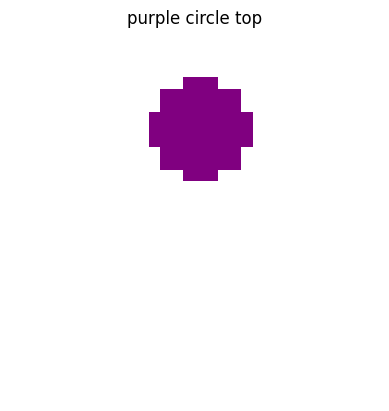

In [56]:
show_sample(full_ds, 120)

# Image Encoder

In [57]:
class ImageEncoder(nn.Module):
    def __init__(self,embed_dim = EMBED_DIM):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(3,32,kernel_size = 3,stride = 2 , padding = 1),
            nn.ReLU(),
            nn.Conv2d(32,64,kernel_size = 3,stride = 2 , padding = 1),
            nn.ReLU(),
            nn.Conv2d(64,128,kernel_size = 3,stride = 2 , padding = 1),
            nn.ReLU(),
            nn.Conv2d(128,256,kernel_size = 3,stride = 2 , padding = 1),
            nn.ReLU()
        )

        self.projection = nn.Linear(256,embed_dim)
        self.layernorm1 = nn.LayerNorm(embed_dim)

    def forward(self,x):
        x = self.conv1(x)
        x = x.mean(dim=[2,3])
        x = self.projection(x)
        x = self.layernorm1(x)
        return x

In [58]:
class TextEncoder(nn.Module):
    def __init__(self,embed_dim = EMBED_DIM , num_heads = ATTENTION_HEAD , vocab_size = VOCAB_SIZE , context_window = 4):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size,embed_dim)
        self.position_embedding = nn.Embedding(context_window,embed_dim)
        self.mha = nn.MultiheadAttention(embed_dim,num_heads)
        self.mlp = nn.Linear(embed_dim,embed_dim)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self,toks):
        N,L = toks.shape
        position_embedding_ids = torch.arange(L,device = toks.device).unsqueeze(0).expand(N,L)
        position_embedding_vectors = self.position_embedding(position_embedding_ids)
        token_embedding_vectors = self.token_embedding(toks)
        x = token_embedding_vectors + position_embedding_vectors
        x = self.mha(x,x,x)[0]
        x = x[:,0]
        x = self.mlp(x)
        x = F.normalize(self.norm(x),dim = 1)
        return x

In [ ]:
class TextEncoder(nn.Module):
    def __init__(self):
        super().__init__(vocab_size = VOCAB_SIZE,embed_dim = EMBED_DIM,context_window = 4,num_heads = ATTENTION_HEADS)
        self.token_embedding = nn.Embedding(vocab_size,embed_dim)
        self.position_embedding = nn.Embedding(context_window , embed_dim)
        self.mha = nn.MultiheadAttention(embed_dim,num_heads,batch_first = True)
        self.mlp = nn.Linear(embed_dim,embed_dim)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self,toks):
        N,L = toks.shape
        position_embedding_ids = torch.arange(L,device = toks.device).unsqueeze(0).expand(N,L)
        position_embedding_vectors = self.position_embedding(position_embedding_ids)
        token_vectors = self.token_embedding(toks)
        x = token_vectors + position_embedding_vectors
        x = self.mha(x,x,x)[0]
        x = [:,0]
        x = self.mlp(x)
        x = self.norm(x)
        x = F.normalize(x,dim = 1)
        return x

In [ ]:
class ImageEncoder(nn.Module):
    def __init__(self,img_size = IMG_SIZE,embed_dim = EMBED_DIM):
        self.conv = nn.Sequential(
            nn.Conv2d(3,32,kernel=3,stride = 2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32,64,kernel=3,stride = 2, padding=1),
            nn.ReLU(),
            nnn.Conv2d(64,128,kernel=3,stride = 2, padding=1),
            nn.ReLU(),
            nn.Conv2d(128,256,kernel=3,stride = 2, padding=1),
            nn.ReLU()
        )
        self.mlp = nn.Linear(256,embed_dim)
        self.layernorm1 = nn.LayerNorm(embed_dim)

    def forward(self,x):
        x = self.conv(x)
        x = x.mean(dim = [2,3])
        x = self.mlp(x)
        x = self.layernorm1(x)
        x = F.normalize(x,dim = 1)
        return x

# Clip Loss

In [59]:
def clip_loss(img_emb,txt_emb,temperature = TEMPERATURE):
    logits = (img_emb @ txt_emb.T)/ temperature
    targets = torch.arange(img_emb.size(0),device = img_emb.device)
    loss_i = F.cross_entropy(logits,targets)
    loss_t = F.cross_entropy(logits.T,targets)
    return ((loss_i + loss_t)/2.0)

# The Model

In [60]:
img_enc = ImageEncoder().to(device)
txt_enc = TextEncoder().to(device)
params = list(img_enc.parameters()) + list(txt_enc.parameters())
optimizer = torch.optim.AdamW(params,lr = LR)

In [61]:
def show_image(t,title = None):
    img = (t.permute(1,2,0).numpy()*255),astype(np.uint8)
    plt.figure(figsize = (2.2,2.2))
    plt.axis('off')
    if title: plt.title(title,fontsize = 8)
    plt.imshow(img) ; plt.show()
    

In [62]:
img_enc.eval()
txt_enc.eval()

with torch.no_grad():

    random_idx = random.randrange(len(full_ds))

    sample_img,sample_toks = full_ds[random_idx]

    sample_img = sample_img.unsqueeze(0).to(device)

    sample_toks = sample_toks.unsqueeze(0).to(device)

    img_emb = img_enc(sample_img)

    txt_emb = txt_enc(sample_toks)

    similarity = (img_emb @ txt_emb.T).item()

print("Caption :",full_ds.captions[random_idx])

print("Similarity :",similarity)

Caption : brown square left
Similarity : -0.04548901319503784


# Training, Validation and Evaluation

In [63]:
# Make sure the vocabulary size is available before creating the text encoder
VOCAB_SIZE = len(full_ds.vocab)

print("VOCAB_SIZE :", VOCAB_SIZE)
print("Train size :", len(train_ds))
print("Val size   :", len(val_ds))


VOCAB_SIZE : 22
Train size : 194
Val size   : 49


In [64]:
# Image Encoder

class ImageEncoder(nn.Module):

    def __init__(self,embed_dim = EMBED_DIM):

        super().__init__()

        self.conv1 = nn.Sequential(

            nn.Conv2d(
                3,
                32,
                kernel_size = 3,
                stride = 2,
                padding = 1
            ),

            nn.ReLU(),

            nn.Conv2d(
                32,
                64,
                kernel_size = 3,
                stride = 2,
                padding = 1
            ),

            nn.ReLU(),

            nn.Conv2d(
                64,
                128,
                kernel_size = 3,
                stride = 2,
                padding = 1
            ),

            nn.ReLU(),

            nn.Conv2d(
                128,
                256,
                kernel_size = 3,
                stride = 2,
                padding = 1
            ),

            nn.ReLU()
        )

        self.projection = nn.Linear(
            256,
            embed_dim
        )

        self.layernorm1 = nn.LayerNorm(
            embed_dim
        )

    def forward(self,x):

        x = self.conv1(x)

        x = x.mean(dim = [2,3])

        x = self.projection(x)

        x = self.layernorm1(x)

        x = F.normalize(
            x,
            dim = 1
        )

        return x


In [65]:
# Text Encoder

class TextEncoder(nn.Module):

    def __init__(
        self,
        embed_dim = EMBED_DIM,
        num_heads = ATTENTION_HEAD,
        vocab_size = VOCAB_SIZE,
        context_window = 4
    ):

        super().__init__()

        self.token_embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        self.position_embedding = nn.Embedding(
            context_window,
            embed_dim
        )

        self.mha = nn.MultiheadAttention(
            embed_dim,
            num_heads,
            batch_first = True
        )

        self.mlp = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.norm = nn.LayerNorm(
            embed_dim
        )

    def forward(self,toks):

        N,L = toks.shape

        position_embedding_ids = torch.arange(
            L,
            device = toks.device
        ).unsqueeze(0).expand(N,L)

        position_embedding_vectors = self.position_embedding(
            position_embedding_ids
        )

        token_embedding_vectors = self.token_embedding(
            toks
        )

        x = (
            token_embedding_vectors
            + position_embedding_vectors
        )

        x = self.mha(
            x,
            x,
            x
        )[0]

        # Take CLS token
        x = x[:,0]

        x = self.mlp(x)

        x = self.norm(x)

        x = F.normalize(
            x,
            dim = 1
        )

        return x


In [66]:
# CLIP Loss

def clip_loss(
    img_emb,
    txt_emb,
    temperature = TEMPERATURE
):

    logits = (
        img_emb @ txt_emb.T
    ) / temperature

    targets = torch.arange(
        img_emb.size(0),
        device = img_emb.device
    )

    loss_i = F.cross_entropy(
        logits,
        targets
    )

    loss_t = F.cross_entropy(
        logits.T,
        targets
    )

    return (loss_i + loss_t) / 2.0


In [67]:
# Create the encoders and optimizer

img_enc = ImageEncoder().to(device)

txt_enc = TextEncoder().to(device)

params = (
    list(img_enc.parameters())
    + list(txt_enc.parameters())
)

optimizer = torch.optim.AdamW(
    params,
    lr = LR
)

print("Image Encoder Parameters :", sum(p.numel() for p in img_enc.parameters()))
print("Text Encoder Parameters  :", sum(p.numel() for p in txt_enc.parameters()))


Image Encoder Parameters : 404992
Text Encoder Parameters  : 22592


In [68]:
# Training and Validation

train_losses = []
val_losses = []

for epoch in range(50):

    img_enc.train()
    txt_enc.train()

    running_loss = 0.0

    for images,tokens in train_loader:

        images = images.to(device)
        tokens = tokens.to(device)

        img_emb = img_enc(images)

        txt_emb = txt_enc(tokens)

        loss = clip_loss(
            img_emb,
            txt_emb
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = (
        running_loss / len(train_loader)
    )

    img_enc.eval()
    txt_enc.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for images,tokens in val_loader:

            images = images.to(device)
            tokens = tokens.to(device)

            img_emb = img_enc(images)

            txt_emb = txt_enc(tokens)

            loss = clip_loss(
                img_emb,
                txt_emb
            )

            running_val_loss += loss.item()

    val_loss = (
        running_val_loss / len(val_loader)
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss : {train_loss:.4f} "
        f"Val Loss : {val_loss:.4f}"
    )


Epoch [1/50] Train Loss : 2.3936 Val Loss : 1.9684
Epoch [2/50] Train Loss : 2.3185 Val Loss : 1.8917
Epoch [3/50] Train Loss : 2.1296 Val Loss : 1.4866
Epoch [4/50] Train Loss : 1.4693 Val Loss : 1.0541
Epoch [5/50] Train Loss : 0.8544 Val Loss : 0.7689
Epoch [6/50] Train Loss : 0.8345 Val Loss : 0.8940
Epoch [7/50] Train Loss : 0.6872 Val Loss : 0.7103
Epoch [8/50] Train Loss : 0.6010 Val Loss : 0.6136
Epoch [9/50] Train Loss : 0.6271 Val Loss : 0.8881
Epoch [10/50] Train Loss : 0.5641 Val Loss : 0.4887
Epoch [11/50] Train Loss : 0.4537 Val Loss : 0.4937
Epoch [12/50] Train Loss : 0.4609 Val Loss : 0.5152
Epoch [13/50] Train Loss : 0.3828 Val Loss : 0.4625
Epoch [14/50] Train Loss : 0.3332 Val Loss : 0.3654
Epoch [15/50] Train Loss : 0.2529 Val Loss : 0.4029
Epoch [16/50] Train Loss : 0.2875 Val Loss : 0.4392
Epoch [17/50] Train Loss : 0.2735 Val Loss : 0.3502
Epoch [18/50] Train Loss : 0.2207 Val Loss : 0.2545
Epoch [19/50] Train Loss : 0.1743 Val Loss : 0.3176
Epoch [20/50] Train L

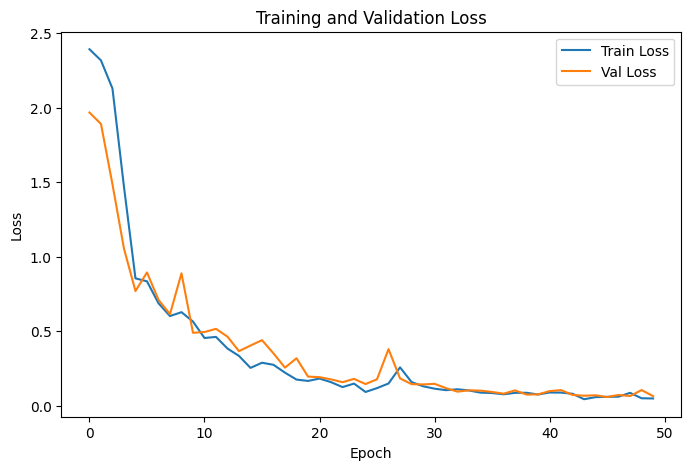

In [69]:
# Plot Training and Validation Loss

plt.figure(figsize = (8,5))

plt.plot(
    train_losses,
    label = "Train Loss"
)

plt.plot(
    val_losses,
    label = "Val Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training and Validation Loss")

plt.legend()

plt.show()


In [70]:
# Helper function for displaying an image

def show_image(t,title = None):

    img = (t.permute(1,2,0).cpu().numpy() * 255).astype(np.uint8)

    plt.figure(figsize = (2.2,2.2))

    plt.axis("off")

    if title:
        plt.title(title,fontsize = 8)

    plt.imshow(img)

    plt.show()


In [71]:
# Encode all captions once

img_enc.eval()
txt_enc.eval()

all_tokens = torch.stack([
    full_ds.encode_text(caption)
    for caption in full_ds.captions
])

all_tokens = all_tokens.to(device)

with torch.no_grad():

    all_text_embeddings = txt_enc(
        all_tokens
    )

print(
    "All text embeddings shape :",
    all_text_embeddings.shape
)


All text embeddings shape : torch.Size([243, 64])


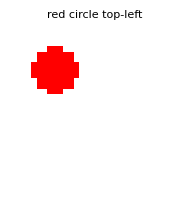

Actual Caption : red circle top-left
Predicted Caption : red circle top-left
Similarity : 0.9146475195884705


In [72]:
# Test Image -> Caption Retrieval

random_idx = random.randrange(
    len(full_ds)
)

sample_img,sample_toks = full_ds[
    random_idx
]

show_image(
    sample_img,
    full_ds.captions[random_idx]
)

with torch.no_grad():

    image_embedding = img_enc(
        sample_img.unsqueeze(0).to(device)
    )

    similarities = (
        image_embedding
        @ all_text_embeddings.T
    ).squeeze(0)

    predicted_idx = similarities.argmax().item()

print(
    "Actual Caption :",
    full_ds.captions[random_idx]
)

print(
    "Predicted Caption :",
    full_ds.captions[predicted_idx]
)

print(
    "Similarity :",
    similarities[predicted_idx].item()
)


In [73]:
# Test Multiple Images

for _ in range(10):

    random_idx = random.randrange(
        len(full_ds)
    )

    sample_img,sample_toks = full_ds[
        random_idx
    ]

    with torch.no_grad():

        image_embedding = img_enc(
            sample_img.unsqueeze(0).to(device)
        )

        similarities = (
            image_embedding
            @ all_text_embeddings.T
        ).squeeze(0)

        predicted_idx = similarities.argmax().item()

    print(
        "Actual :",
        full_ds.captions[random_idx]
    )

    print(
        "Predicted :",
        full_ds.captions[predicted_idx]
    )

    print(
        "Similarity :",
        similarities[predicted_idx].item()
    )

    print("-" * 50)


Actual : gray square top-right
Predicted : gray square top-right
Similarity : 0.8988848328590393
--------------------------------------------------
Actual : red circle center
Predicted : red circle center
Similarity : 0.8777484893798828
--------------------------------------------------
Actual : gray square bottom-left
Predicted : gray square bottom-left
Similarity : 0.8856079578399658
--------------------------------------------------
Actual : red square left
Predicted : brown square left
Similarity : 0.8903486728668213
--------------------------------------------------
Actual : gray triangle left
Predicted : gray triangle left
Similarity : 0.8895949125289917
--------------------------------------------------
Actual : orange square top-left
Predicted : yellow square top-left
Similarity : 0.8547849059104919
--------------------------------------------------
Actual : brown square bottom-left
Predicted : brown square bottom-left
Similarity : 0.9134523868560791
---------------------------

## Image-Text Similarity Matrix

For one batch, the diagonal entries should become large because image `i`
should match caption `i`.


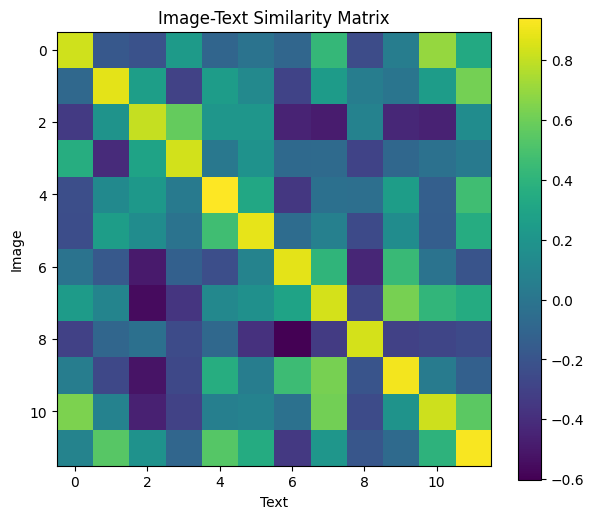

In [74]:
# Visualize the image-text similarity matrix

img_enc.eval()
txt_enc.eval()

images,tokens = next(iter(val_loader))

images = images.to(device)
tokens = tokens.to(device)

with torch.no_grad():

    img_emb = img_enc(images)

    txt_emb = txt_enc(tokens)

    similarity_matrix = img_emb @ txt_emb.T

plt.figure(figsize = (7,6))

plt.imshow(
    similarity_matrix.cpu().numpy()
)

plt.colorbar()

plt.xlabel("Text")
plt.ylabel("Image")

plt.title("Image-Text Similarity Matrix")

plt.show()


## Final Model Check

The model trained above is a CLIP-style contrastive vision-language model.
It learns a shared image/text embedding space and performs image-to-text
retrieval. It does not yet generate new caption tokens autoregressively.
